In [ ]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import silhouette_score

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.cluster import  KMeans

from sklearn.decomposition import PCA


ID_COLUNA = 'ID_DOMICILIO'
PESO_COLUNA = 'PESO_AMOSTRAL'
TARGET = 'DEPRESSAO_PHQ_SIMPLIFICADO'

COLUNAS_SINTOMAS_DEPRESSAO = [
    'FREQ_PERDA_INTERESSE_2SEM',
    'FREQ_SENTIU_DEPRIMIDO_2SEM',
    'FREQ_DIFICULDADE_DORMIR_2SEM',
    'FREQ_CANSASO_2SEM',
    'FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM',
    'FREQ_AUTOAVALIACAO_NEGTIVA_2SEM',
    'FREQ_DIFICULDADE_CONCENTRACAO_2SEM',
    'MODIFICACAO_VELOCIDADE_FALA',
    'FREQ_DEPRESSAO',
    'REMEDIO_DEPRESSAO',
    'HISTORICO_DEPRESSAO',
    'INTENSIDADE_DEPRESSAO'
]

# 1. Carregar a base limpa e definir o ID como índice
df = pd.read_csv(Path("../4_random_forest") / "adult25_limpo.csv").set_index(ID_COLUNA)
df["DEPRESSAO_PHQ_SIMPLIFICADO"] = ((df["SEVERIDADE_DEPRESSAO_PHQ"] != 1)&(df["SEVERIDADE_DEPRESSAO_PHQ"] != -1)).astype(int)

# 2. Eliminar os registros indefinidos no TARGET (-1 e 5)
df = df[~df[TARGET].isin([-1, 5])].copy()

# 3. Isolar Target (y), Peso Amostral e Features Preditoras (X)
y = df[TARGET]
sample_weights = df[PESO_COLUNA]
colunas_remover = [TARGET, PESO_COLUNA] + COLUNAS_SINTOMAS_DEPRESSAO
X = df.drop(columns=[col for col in colunas_remover if col in df.columns])

In [35]:
# Pré-processamento
num_cols = ['RAZAO_RENDA_POBREZA','IDADE']
cat_cols = [col for col in X.columns if col not in num_cols]

preprocessor_A = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols)
    ]
)

X_proc = preprocessor_A.fit_transform(X)

X_proc = pd.DataFrame(X_proc, columns=preprocessor_A.get_feature_names_out(), index=X.index)

X_proc.head()

,num__RAZAO_RENDA_POBREZA,num__IDADE,cat__SEXO_1,cat__SEXO_2,cat__CLASSIFICACAO_URBANO_RURAL_2,cat__CLASSIFICACAO_URBANO_RURAL_3,cat__CLASSIFICACAO_URBANO_RURAL_4,cat__REGIAO_GEOGRAFICA_2,cat__REGIAO_GEOGRAFICA_3,cat__REGIAO_GEOGRAFICA_4,...,cat__FREQUENCIA_FALHA_MEMORIA_3,cat__FREQUENCIA_FALHA_MEMORIA_4,cat__TIPO_DIFICULDADE_COGNITIVA_1,cat__TIPO_DIFICULDADE_COGNITIVA_2,cat__TIPO_DIFICULDADE_COGNITIVA_3,cat__TIPO_DIFICULDADE_COGNITIVA_4,cat__QTD_DIFICULDADE_COGNITIVA_1,cat__QTD_DIFICULDADE_COGNITIVA_2,cat__QTD_DIFICULDADE_COGNITIVA_3,cat__QTD_DIFICULDADE_COGNITIVA_4
ID_DOMICILIO,,,,,,,,,,,,,,,,,,,,,
H012128,-0.876563,0.908759,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
H000617,-0.001807,0.696469,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
H033243,-1.323519,-1.851016,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
H049140,0.636701,0.908759,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0
H012797,0.183360,0.059597,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0


In [36]:
km = KMeans(n_clusters=2,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=42
        )
labels = pd.Series(
    km.fit_predict(X_proc),
    index=X_proc.index,
    name="cluster",
)
inercia = km.inertia_
silhouettes = silhouette_score(X_proc, labels)


target  cluster
0       1          11376
        0           7824
1       1           2791
        0           2224
Name: count, dtype: int64
Proporção (%) dentro de cada cluster:
target      0     1
cluster            
0        77.9  22.1
1        80.3  19.7


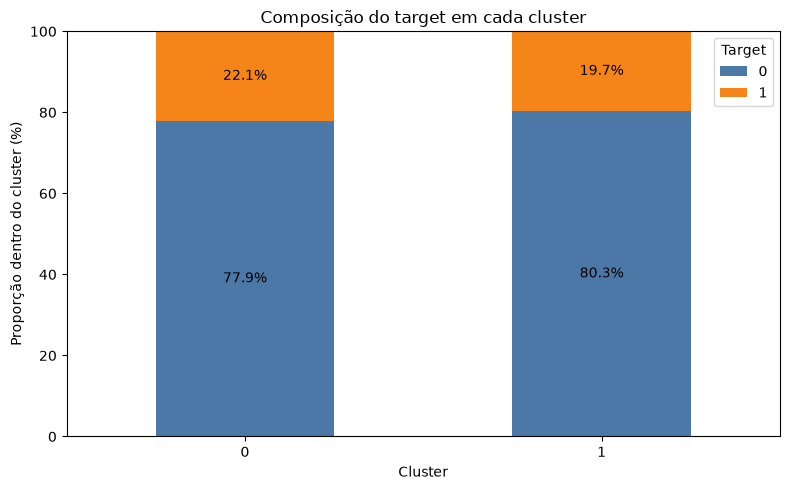

In [37]:
resultado = pd.DataFrame({
    "target": y,
    "cluster": labels,
})

print(resultado.sort_values("target").value_counts())

contagens = pd.crosstab(resultado["cluster"], resultado["target"])
proporcoes = contagens.div(contagens.sum(axis=1), axis=0).mul(100)

print("Proporção (%) dentro de cada cluster:")
print(proporcoes.round(1))

ax = proporcoes.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#4C78A8", "#F58518"],
)

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f%%", label_type="center")

ax.set(
    title="Composição do target em cada cluster",
    xlabel="Cluster",
    ylabel="Proporção dentro do cluster (%)",
)
ax.legend(title="Target")
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

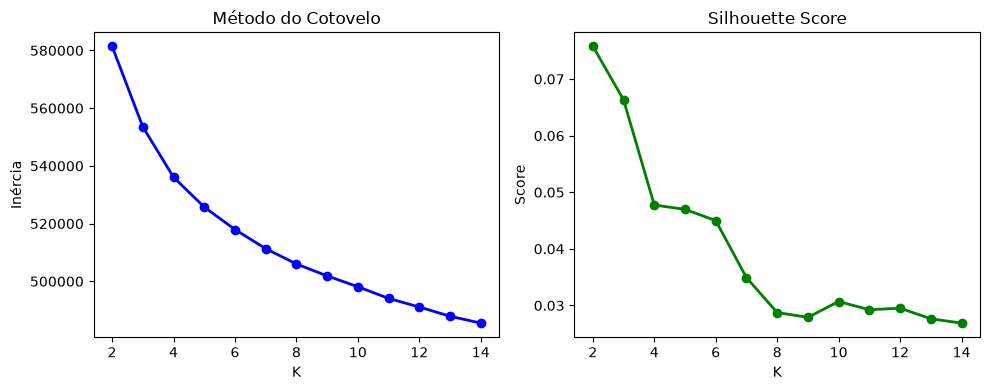

In [38]:
inercias, silhouettes = [], []
ks = range(2,15)
for k in ks:
    km = KMeans(n_clusters=k,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=42
        )
    labels = km.fit_predict(X_proc)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_proc, labels))



# Plotar diagnóstico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.plot(ks, inercias, 'bo-', linewidth=2)
ax1.set_title('Método do Cotovelo'); ax1.set_xlabel('K'); ax1.set_ylabel('Inércia')
ax2.plot(ks, silhouettes, 'go-', linewidth=2)
ax2.set_title('Silhouette Score'); ax2.set_xlabel('K'); ax2.set_ylabel('Score')
plt.tight_layout(); plt.show()


Proporção (%) dentro de cada cluster:
target      0     1
cluster            
0        35.1  64.9
1        87.2  12.8
2        94.9   5.1


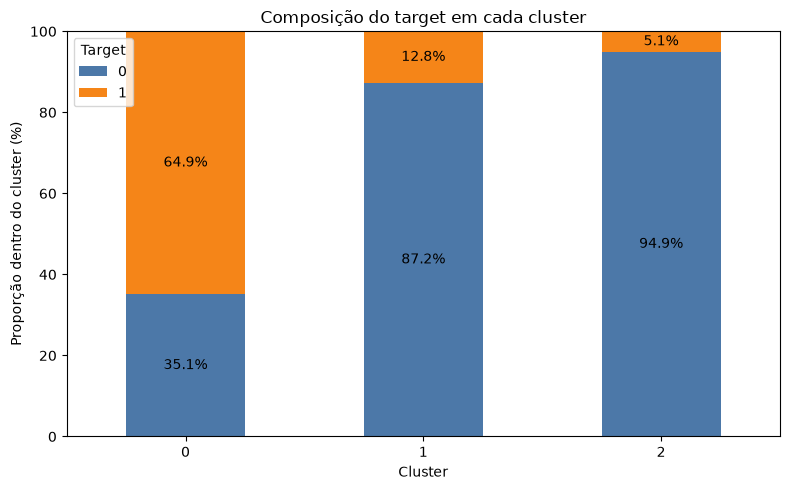

In [39]:
km = KMeans(n_clusters=3,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=42
        )
labels = pd.Series(
    km.fit_predict(X_proc),
    index=X_proc.index,
    name="cluster",
)
inercia = km.inertia_
silhouettes = silhouette_score(X_proc, labels)


resultado = pd.DataFrame({
    "target": y,
    "cluster": labels,
})

contagens = pd.crosstab(resultado["cluster"], resultado["target"])
proporcoes = contagens.div(contagens.sum(axis=1), axis=0).mul(100)

print("Proporção (%) dentro de cada cluster:")
print(proporcoes.round(1))

ax = proporcoes.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#4C78A8", "#F58518"],
)

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f%%", label_type="center")

ax.set(
    title="Composição do target em cada cluster",
    xlabel="Cluster",
    ylabel="Proporção dentro do cluster (%)",
)
ax.legend(title="Target")
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Proporção (%) dentro de cada cluster:
target      0     1
cluster            
0        31.4  68.6
1        93.7   6.3
2        86.3  13.7
3        93.5   6.5


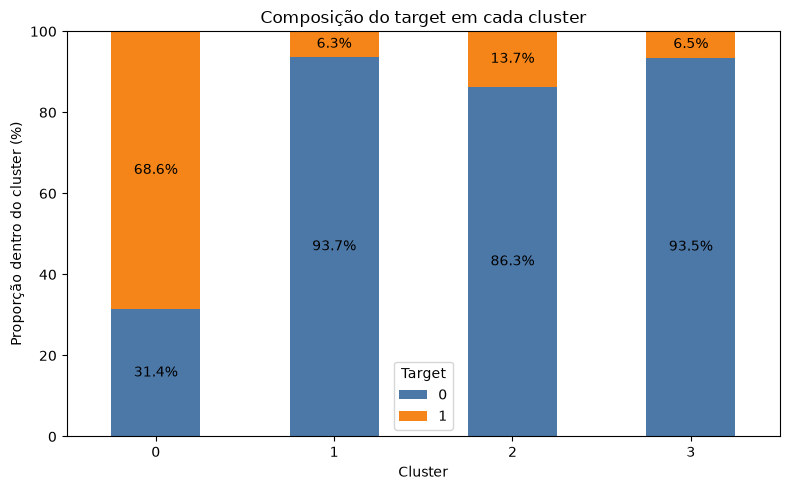

In [40]:
km = KMeans(n_clusters=4,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=42
        )
labels = pd.Series(
    km.fit_predict(X_proc),
    index=X_proc.index,
    name="cluster",
)
inercia = km.inertia_
silhouettes = silhouette_score(X_proc, labels)


resultado = pd.DataFrame({
    "target": y,
    "cluster": labels,
})

contagens = pd.crosstab(resultado["cluster"], resultado["target"])
proporcoes = contagens.div(contagens.sum(axis=1), axis=0).mul(100)

print("Proporção (%) dentro de cada cluster:")
print(proporcoes.round(1))

ax = proporcoes.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#4C78A8", "#F58518"],
)

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f%%", label_type="center")

ax.set(
    title="Composição do target em cada cluster",
    xlabel="Cluster",
    ylabel="Proporção dentro do cluster (%)",
)
ax.legend(title="Target")
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Proporção (%) dentro de cada cluster:
target      0     1
cluster            
0        93.6   6.4
1        40.5  59.5
2        94.6   5.4
3        34.7  65.3
4        95.0   5.0


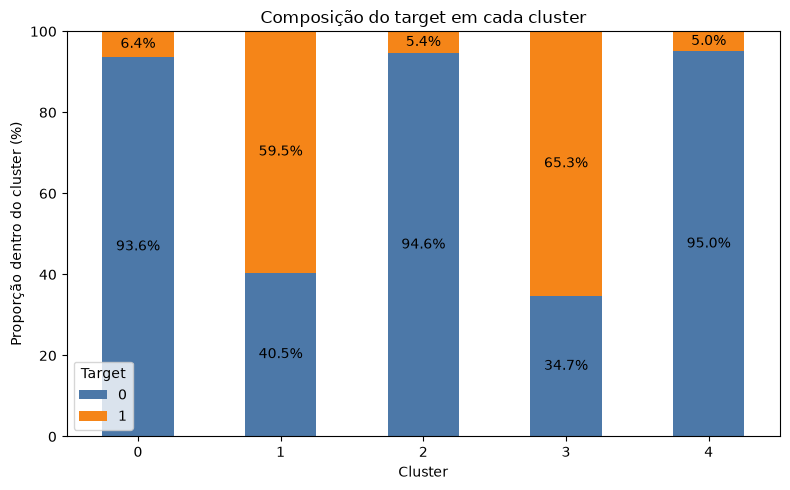

In [41]:
km = KMeans(n_clusters=5,
            init='k-means++',
            n_init=10,
            max_iter=300,
            tol=1e-4,
            random_state=42
        )
labels = pd.Series(
    km.fit_predict(X_proc),
    index=X_proc.index,
    name="cluster",
)
inercia = km.inertia_
silhouettes = silhouette_score(X_proc, labels)


resultado = pd.DataFrame({
    "target": y,
    "cluster": labels,
})

contagens = pd.crosstab(resultado["cluster"], resultado["target"])
proporcoes = contagens.div(contagens.sum(axis=1), axis=0).mul(100)

print("Proporção (%) dentro de cada cluster:")
print(proporcoes.round(1))

ax = proporcoes.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["#4C78A8", "#F58518"],
)

for barras in ax.containers:
    ax.bar_label(barras, fmt="%.1f%%", label_type="center")

ax.set(
    title="Composição do target em cada cluster",
    xlabel="Cluster",
    ylabel="Proporção dentro do cluster (%)",
)
ax.legend(title="Target")
ax.set_ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()